# 12 · New and revised figures of the Results section

This notebook draws only the figures that change after the review of the article. Notebook 11 stays as it is for the
other figures (Figs. 8, 9, 11, S1 and S2). Nothing is retrained; the run reads the saved predictions of notebooks 07 to 10
and takes a few minutes on a CPU.

| File | Place in the article | What changed |
|---|---|---|
| `fig07_regression_source` | new Fig. 7, start of Section V | **new.** Why the updates regress: (a) per-class AP change against the legacy model, (b) where the legacy-detected positives fall relative to the update's thresholds, (c) RFMiD 2.0 images of near misses |
| `fig10_validity` | Fig. 10, Section V-D | **extended.** Panels (a) to (c) as before; new (d) achieved risk against the requested level $\alpha$ from 2% to 30%, and (e) the false-alarm cost of the certificate in both settings, with the spread over seeds. Replaces Fig. S3 |
| `fig12_examples` | Fig. 12, Section V-E | **revised.** Each image now has a threshold ruler that shows why the decision changes, and the last column is a failure case |
| `figS4_ablation` | Fig. S4, supplement | the former Fig. 7 (`fig07_ablation`) is copied under its new name if notebook 11 has produced it |

`figS3_calibration_size` is no longer used: Fig. 10(e) shows the same seed spread. Fig. S2 stays as drawn by notebook 11.

Outputs go to `outputs/figures/article/` (vector PDF, 600 dpi PNG) and the plotted numbers to `outputs/figures/article/data/`.
Every printed check must pass before a figure is used: the rebuilt numbers have to match the summaries of notebooks 08 and 10.

**Run order.** Notebooks 07, 08, 09 and 10 must have finished. Run all cells from the `notebooks` folder.

## 0. Configuration

In [22]:
QUICK = False                         # must match the runs of notebooks 07 to 10
SEEDS = [0] if QUICK else [0, 1, 2]
K_FOLDS = 5
EXAMPLE_SEED = 0                      # seed whose predictions are shown in Fig. 12
N_EXAMPLES = (2, 1, 1)                # Fig. 12: finding restored (no new alarm), restored (with a new alarm), still missed

CFG = dict(ct_eps=0.0, alphas=(0.05, 0.10), ltt_delta=0.10, min_pos=5, shape_dup_thr=5)
PLUG = ["FT", "KD", "FD", "WiSE", "OE", "MPT", "RA-LDL", "HCP", "RCLP", "CRCL", "Joint"]
COMPETITORS = ["MPT", "RA-LDL", "HCP", "RCLP", "CRCL"]
OURS = "OE+CURE10"
S2_METHODS = ["New", "New-FD"]
import numpy as _np; GRID = _np.linspace(-8, 8, 801)
UPDATE_7 = "OE"                       # Fig. 7(b, c): update whose thresholds are examined
N_NEAR = 5                            # Fig. 7(c): number of near-miss images (one per class)
NEAR_LOGIT = 1.0                      # Fig. 7: a miss is "near" when the score is within this many logits of the threshold

## 1. Setup, style and helpers

In [23]:
import json, sys, time, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
from scipy import stats
from PIL import Image
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config, audit, cure, cv, crc, frontier, certify

OUT = config.OUTPUT_DIR
CACHE, RES = OUT / "cache", OUT / "results"
q = "_quick" if QUICK else ""
CV04, RAW, RAW8, RAW9, RAW10, S2DIR = (RES / f"cv{q}", RES / f"cv07{q}", RES / f"cv08{q}", RES / f"cv09{q}",
                                       RES / f"cv10{q}", RES / f"s2_07{q}")
SUM10, SUM08 = RES / f"main10_summary{q}.json", RES / f"main08_summary{q}.json"
FIG = config.FIGURE_DIR / ("article_quick" if QUICK else "article")
(FIG / "data").mkdir(parents=True, exist_ok=True)
need = [CV04 / "folds.csv", SUM10, SUM08] + [RAW / f"legacy__s{s}.npz" for s in SEEDS] + [S2DIR / f"legacy__s{s}.npz" for s in SEEDS]
miss = [p for p in need if not p.exists()]
assert not miss, f"Run notebooks 07 to 10 first: {miss[0]} not found"
J10, J08 = json.loads(SUM10.read_text()), json.loads(SUM08.read_text())
print("summaries loaded:", J10["notebook"], J10["verdict"], "|", J08["notebook"], J08["verdict"])

# ---------------------------------------------------------------- style (IEEE two-column)
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7.5, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
    "legend.fontsize": 6.3, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "lines.linewidth": 1.0, "lines.solid_capstyle": "round",
    "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "mathtext.default": "regular", "figure.dpi": 150, "savefig.dpi": 600, "axes.titlelocation": "left",
})
COL1, COL2 = 3.5, 7.16
# Okabe-Ito; colour follows the method in every figure
CURE_C = "#0072B2"                                           # CURE (our method) in every figure
COL = {"OE": "#3B4450", "HCP": "#E69F00", "RCLP": "#56B4E9", "CRCL": "#009E73", "MPT": "#CC79A7", "RA-LDL": "#D55E00"}
GREY, GREY_D, INK = "#A3A9B0", "#6E7781", "#1A1A1A"
BAD, FA_C, N_C = "#D55E00", "#E69F00", "#CC79A7"              # limit line / false alarm / counts
KEPT_C, MISS_C = "#009E73", "#D55E00"
NICE = {"WiSE": "WiSE-FT", "Joint": "Joint retraining", "Select": "Per-class selection", "Legacy-recal": "Legacy, recalibrated"}
XL = "New false alarms relative to the legacy model,\nNFR$^{-}$ (% of negative labels)"
YL = "Missed-disease flips relative to the legacy\nmodel, NFR$^{+}$ (% of positive labels)"
nice = lambda m: NICE.get(m, m)
mcol = lambda m: COL.get(m, GREY_D)


def save(fig, name, data=None):
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight", pad_inches=0.02)
    fig.savefig(FIG / f"{name}.png", dpi=600, bbox_inches="tight", pad_inches=0.02)
    if data is not None:
        data.to_csv(FIG / "data" / f"{name}.csv", index=False)
    print("saved", FIG / f"{name}.pdf")


def dotted_legend(ax, **kw):
    leg = ax.legend(frameon=True, fancybox=False, borderpad=0.4, handlelength=1.6, **kw)
    fr = leg.get_frame()
    fr.set_linestyle((0, (1, 1.5))); fr.set_edgecolor("#8C959F"); fr.set_linewidth(0.6); fr.set_facecolor("white"); fr.set_alpha(1)
    return leg


def color_ticks(labels, methods):
    """Colour each tick label with the colour of its method."""
    for t, m in zip(labels, methods):
        t.set_color(CURE_C if m == "CURE" else mcol(m))


def panel_tag(ax, s, x=-0.16, y=1.04):
    ax.text(x, y, f"({s})", transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom", ha="left")


def repel(ys, min_gap):
    """Spread label positions (sorted input order kept) so neighbours are at least min_gap apart."""
    ys = np.asarray(ys, float)
    o = np.argsort(ys)
    out = ys[o].copy()
    for _ in range(200):
        moved = False
        for i in range(1, len(out)):
            d = out[i] - out[i - 1]
            if d < min_gap:
                shift = (min_gap - d) / 2
                out[i - 1] -= shift; out[i] += shift; moved = True
        if not moved:
            break
    res = np.empty_like(out)
    res[o] = out
    return res


def m10(name):
    """Seed means of one row of the main table (notebook 10)."""
    r = J10["means"][name]
    return {"mAPsh": r["mAPsh"], "mAP": r["mAP"], "NFR+": r["NFR+"][0], "NFR+sd": r["NFR+"][1],
            "NFR-": r["NFR-"][0], "NFR-sd": r["NFR-"][1], "risk": r["risk"]}

import shutil
from matplotlib.ticker import FixedLocator, NullLocator
LOGIT = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
SIG = lambda z: 1 / (1 + np.exp(-z))
order = sorted(PLUG, key=lambda m: m10(m)["NFR+"])           # update order used in Figs. 9 and 10


def framed(leg):
    leg.get_frame().set_linestyle((0, (1, 1.5))); leg.get_frame().set_edgecolor("#8C959F"); leg.get_frame().set_linewidth(0.6)
    return leg

summaries loaded: 10_cure_2025_baselines CONFIRMED | 08_confirm_and_main_tables CONFIRMED-FULL


## 2. Manifests, label space and labels of the pooled RFMiD 2.0 set

In [24]:
M = config.MANIFEST_DIR
man1 = {s: pd.read_csv(M / f"rfmid1_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
man2 = {s: pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
space = json.load(open(M / "label_space.json"))

classes1 = space["rfmid1_classes"]                       # 45, legacy output order
new2 = space["new"]                                      # 12 RFMiD 2.0-only (2.0 column names)
UNION = classes1 + new2                                  # 57 = update model output space
N_OLD = len(classes1)
shared_map = space["shared_map"]                         # 1.0 name -> 2.0 column
SH = [UNION.index(c) for c in shared_map]                # union indices of shared classes
RT = [UNION.index(c) for c in space["retired"]]          # retired (1.0 only)
NW = list(range(N_OLD, len(UNION)))                      # new (2.0 only)
OLD = list(range(N_OLD))
print(f"union {len(UNION)} = shared {len(SH)} + retired {len(RT)} + new {len(NW)}")

union 57 = shared 38 + retired 7 + new 12


In [25]:
folds_df = pd.read_csv(CV04 / "folds.csv", dtype={"ID": str})
man2_all = pd.concat([pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS], ignore_index=True)
pool = folds_df.merge(man2_all, on=["split", "ID"], how="left", validate="one_to_one")
folds, groups = pool["fold"].values, pool["group"].values

def label_arrays(man, dataset):
    n = len(man)
    Y = np.zeros((n, len(UNION)), dtype=np.float32)
    Mk = np.zeros_like(Y)
    if dataset == "rfmid1":
        Y[:, OLD] = man[classes1].values
        Mk[:, OLD] = 1
    else:
        for c1, c2 in shared_map.items():
            j = UNION.index(c1)
            Y[:, j], Mk[:, j] = man[c2].values, 1
        for c2 in new2:
            j = UNION.index(c2)
            Y[:, j], Mk[:, j] = man[c2].values, 1
    return Y, Mk

Yp, Mp = label_arrays(pool, "rfmid2")
Y1v, M1v = label_arrays(man1["val"], "rfmid1")
Y1t, M1t = label_arrays(man1["test"], "rfmid1")
HR = UNION.index("HR") if "HR" in UNION else None
GROUPS = {"shared": SH, "new": NW, "all": SH + NW, "all_exHR": [c for c in SH + NW if c != HR]}
fp1 = pd.read_csv(CACHE / "fingerprints_rfmid1.csv", dtype={"ID": str})
fp2 = pd.read_csv(CACHE / "fingerprints_rfmid2.csv", dtype={"ID": str})
v1val_fp = man1["val"][["split", "ID"]].merge(fp1, on=["split", "ID"], how="left")
pool_fp = pool[["split", "ID"]].merge(fp2, on=["split", "ID"], how="left")
dmin, _ = audit.hamming_min(v1val_fp["phash"], pool_fp["phash"])
KEEP1V = dmin > CFG["shape_dup_thr"]
print(f"pooled RFMiD 2.0: {len(pool)} images; anchoring set: {KEEP1V.sum()} of {len(KEEP1V)} RFMiD 1.0 validation images")

pooled RFMiD 2.0: 748 images; anchoring set: 631 of 640 RFMiD 1.0 validation images


## 3. Rebuild the main-setting predictions with CURE (same code as notebooks 10 and 11)

In [26]:
def raw_file(model, seed, fold):
    return RAW / f"{model}__s{seed}__f{fold}.npz"

def load_raw(model, seed, fold):
    if model == "FD":
        return np.load(RAW8 / f"FD__s{seed}__f{fold}.npz")
    if model in ("FT", "WiSE", "OE"):
        return np.load(raw_file(model, seed, fold))
    if model in ("HCP", "RCLP", "CRCL"):
        return np.load(RAW10 / f"{model}__s{seed}__f{fold}.npz")
    return np.load(RAW9 / f"{model}__s{seed}__f{fold}.npz")

def per_class_miss(VAR, LEG, names, Y, M, cls_idx, min_caught=5):
    rows = []
    for j, c in enumerate(cls_idx):
        rec = {"class": UNION[c]}
        for n in names:
            miss = tot = 0
            for s in SEEDS:
                L, T = VAR[(n, s)]
                Lo, to = LEG[s]
                caught = crc.legacy_caught(Lo, to, Y, M, cls_idx)[:, j]
                pred = L[:, c] >= cure.logit(T[:, c])
                miss += int((caught & ~pred).sum()); tot += int(caught.sum())
            rec["n_caught"] = tot / len(SEEDS)
            rec[n] = 100 * miss / tot if tot else np.nan
        rows.append(rec)
    df = pd.DataFrame(rows)
    return df[df["n_caught"] >= min_caught].sort_values("n_caught", ascending=False).reset_index(drop=True)

In [27]:
VAR, INFO, LEG = {}, [], {}
for seed in SEEDS:
    z = np.load(RAW / f"legacy__s{seed}.npz")
    L_old, thr_old, L1v_old = z["L"], z["thr"], z["L1v"]
    LEG[seed] = (L_old, thr_old)
    fallback = np.where(np.arange(len(UNION)) < N_OLD, thr_old, 0.5)
    caught_all = crc.legacy_caught(L_old, thr_old, Yp, Mp, SH)
    VAR[("Legacy", seed)] = (L_old, np.broadcast_to(thr_old, L_old.shape).copy())
    acc = {}
    for k in range(K_FOLDS):
        te = np.where(folds == k)[0]
        va = np.where(folds == (k + 1) % K_FOLDS)[0]
        Yv, Mv, lo_va = Yp[va], Mp[va], L_old[va]
        acc.setdefault("Legacy-recal", []).append((te, L_old[te], cv.plain_thresholds(lo_va, Yv, Mv, fallback)))
        ft = load_raw("FT", seed, k)
        Ls_va, _ = cure.per_class_select(ft["Lva"], lo_va, Yv, Mv, ft["Lva"], lo_va, SH, RT)
        Ls_te, _ = cure.per_class_select(ft["Lva"], lo_va, Yv, Mv, ft["Lte"], L_old[te], SH, RT)
        acc.setdefault("Select", []).append((te, Ls_te, cv.plain_thresholds(Ls_va, Yv, Mv, fallback)))
        for m in PLUG:
            try:
                r = load_raw(m, seed, k)
            except FileNotFoundError:
                continue
            Lva, Lte, L1v = r["Lva"], r["Lte"], r["L1v"]
            plain = cv.plain_thresholds(Lva, Yv, Mv, fallback)
            s = certify.fit_shape("ct", L1v[KEEP1V], Y1v[KEEP1V], M1v[KEEP1V], L1v_old[KEEP1V], thr_old, SH, fallback, None, CFG["ct_eps"])
            base = plain.copy()
            base[SH] = s[SH]
            caught_v = crc.legacy_caught(lo_va, thr_old, Yv, Mv, SH)
            acc.setdefault(m, []).append((te, Lte, plain))
            for a, tag, meth in [(0.10, "10", "CRC"), (0.05, "5", "CRC"), (0.10, "-LTT10", "LTT")]:
                if meth == "CRC":
                    lam, n_cal, ok = crc.calibrate(Lva, base, caught_v, SH, a, GRID)
                else:
                    lam, n_cal, ok = certify.ltt_calibrate(Lva, base, caught_v, SH, a, CFG["ltt_delta"], GRID)
                t = crc.shift_thresholds(base, SH, lam)
                name = f"{m}+CURE{tag}"
                acc.setdefault(name, []).append((te, Lte, t))
                risk = crc.image_losses(Lte, t, caught_all[te], SH)
                INFO.append({"variant": name, "seed": seed, "fold": k, "alpha": a, "method": meth, "lam": lam, "n_cal": n_cal,
                             "feasible": bool(ok), "test_risk": float(risk.mean()) if len(risk) else np.nan})
    for name, parts in acc.items():
        if len(parts) != K_FOLDS:
            print(f"  skipped {name} (seed {seed}): only {len(parts)} of {K_FOLDS} folds available")
            continue
        L = np.zeros((len(pool), len(UNION)), np.float32)
        T = np.zeros_like(L)
        for te, Lte, t in parts:
            L[te], T[te] = Lte, t[None, :]
        VAR[(name, seed)] = (L, T)
info = pd.DataFrame(INFO)
NAMES = [n for n in ["Legacy", "Legacy-recal", "Select"] + [f"{m}{s}" for m in PLUG for s in ("", "+CURE10", "+CURE5", "+CURE-LTT10")]
         if all((n, s) in VAR for s in SEEDS)]
print(f"{len(NAMES)} rows:", NAMES)

47 rows: ['Legacy', 'Legacy-recal', 'Select', 'FT', 'FT+CURE10', 'FT+CURE5', 'FT+CURE-LTT10', 'KD', 'KD+CURE10', 'KD+CURE5', 'KD+CURE-LTT10', 'FD', 'FD+CURE10', 'FD+CURE5', 'FD+CURE-LTT10', 'WiSE', 'WiSE+CURE10', 'WiSE+CURE5', 'WiSE+CURE-LTT10', 'OE', 'OE+CURE10', 'OE+CURE5', 'OE+CURE-LTT10', 'MPT', 'MPT+CURE10', 'MPT+CURE5', 'MPT+CURE-LTT10', 'RA-LDL', 'RA-LDL+CURE10', 'RA-LDL+CURE5', 'RA-LDL+CURE-LTT10', 'HCP', 'HCP+CURE10', 'HCP+CURE5', 'HCP+CURE-LTT10', 'RCLP', 'RCLP+CURE10', 'RCLP+CURE5', 'RCLP+CURE-LTT10', 'CRCL', 'CRCL+CURE10', 'CRCL+CURE5', 'CRCL+CURE-LTT10', 'Joint', 'Joint+CURE10', 'Joint+CURE5', 'Joint+CURE-LTT10']


Consistency check against the main table of notebook 10.

In [28]:
def seed_points(VARd, LEGd, names, Y, M, idx):
    return {(n, s): frontier.point(frontier.flip_sets(*VARd[(n, s)], LEGd[s][0], LEGd[s][1], Y, M, idx))
            for n in names for s in SEEDS}

check = [n for n in NAMES if n in J10["means"] and n != "Legacy"]
P1 = seed_points(VAR, LEG, check, Yp, Mp, SH)
dev = []
for n in check:
    x = np.mean([P1[(n, s)][0] for s in SEEDS]); y = np.mean([P1[(n, s)][1] for s in SEEDS])
    dev.append((n, abs(x - J10["means"][n]["NFR-"][0]), abs(y - J10["means"][n]["NFR+"][0])))
dev = pd.DataFrame(dev, columns=["variant", "|dNFR-|", "|dNFR+|"])
worst = dev[["|dNFR-|", "|dNFR+|"]].max().max()
print(f"largest deviation from main10_summary.json: {worst:.3f} points over {len(dev)} rows")
assert worst < 0.02, "rebuilt predictions differ from notebook 10; rerun notebook 10 or check QUICK"

largest deviation from main10_summary.json: 0.005 points over 46 rows


## 4. Rebuild the second-setting predictions (same code as notebook 08)

In [29]:
TAGS = [int(round(100 * a)) for a in CFG["alphas"]]
def s2_file(model, seed):
    return S2DIR / f"{model}__s{seed}.npz"
VAR2, INFO2, LEG2 = {}, [], {}
if True:
    Y1t45, M1t45 = Y1t[:, :N_OLD], M1t[:, :N_OLD]
    Y1v45, M1v45 = Y1v[:, :N_OLD], M1v[:, :N_OLD]
    n_te = len(Y1t45)
    for seed in SEEDS:
        z = np.load(S2DIR / f"legacy__s{seed}.npz")
        Lo_v, Lo_t, thr_o = z["Lva"], z["Lte"], z["thr"]
        LEG2[seed] = (Lo_t, thr_o)
        VAR2[("Legacy", seed)] = (Lo_t, np.broadcast_to(thr_o, Lo_t.shape).copy())
        raw = {m: np.load(s2_file(m, seed)) for m in S2_METHODS}
        logits = {m: (raw[m]["Lva"], raw[m]["Lte"]) for m in S2_METHODS}
        logits["OE"] = tuple(cure.output_ensemble(l, lo, N_OLD) for l, lo in zip(logits["New"], (Lo_v, Lo_t)))
        H = crc.split_halves(np.arange(n_te), 7000 + seed)              # same halves as notebook 07
        caught_t = crc.legacy_caught(Lo_t, thr_o, Y1t45, M1t45, OLD)
        for m, (Lv, Lt) in logits.items():
            fit = lambda kind: certify.fit_shape(kind, Lv, Y1v45, M1v45, Lo_v, thr_o, OLD, thr_o, None, CFG["ct_eps"])
            ct, un, leg = fit("ct"), fit("uniform"), thr_o.copy()
            full = lambda t: np.broadcast_to(t, Lt.shape).copy()
            T = {m: full(un), f"{m}+CT": full(ct), f"{m}+LEG": full(leg)}
            for a, tag in zip(CFG["alphas"], TAGS):
                plan = [("CRC", ct, "CRC"), ("CRCu", un, "CRC"), ("CRCleg", leg, "CRC"), ("LTT", ct, "LTT"), ("LTTu", un, "LTT")]
                for short, base, meth in plan:
                    name = f"{m}+{short}{tag}"
                    T[name] = np.zeros_like(Lt)
                    for h in (0, 1):
                        ev, cal = H[h], H[1 - h]
                        if meth == "CRC":
                            lam, n_cal, ok = crc.calibrate(Lt[cal], base, caught_t[cal], OLD, a, GRID)
                        else:
                            lam, n_cal, ok = certify.ltt_calibrate(Lt[cal], base, caught_t[cal], OLD, a, CFG["ltt_delta"], GRID)
                        t = crc.shift_thresholds(base, OLD, lam)
                        T[name][ev] = t[None, :]
                        risk = crc.image_losses(Lt[ev], t, caught_t[ev], OLD)
                        INFO2.append({"variant": name, "seed": seed, "half": h, "alpha": a, "method": meth, "lam": lam,
                                      "n_cal": n_cal, "feasible": bool(ok), "test_risk": float(risk.mean()) if len(risk) else np.nan})
            for name, t in T.items():
                VAR2[(name, seed)] = (Lt, t)
    info2 = pd.DataFrame(INFO2)
    NAMES2 = sorted({n for n, _ in VAR2}, key=lambda n: (n != "Legacy", n.split("+")[0], n))
    print(f"scenario 2: {len(NAMES2)} variants")

scenario 2: 40 variants


In [30]:
check2 = [n for n in ["New", "New-FD", "OE", "OE+CRC10", "OE+CRC5", "OE+LTT10", "OE+LTT5"] if n in J08["s2"]["means"]]
P2s = seed_points(VAR2, LEG2, check2, Y1t45, M1t45, OLD)
worst2 = max(max(abs(np.mean([P2s[(n, s)][0] for s in SEEDS]) - J08["s2"]["means"][n]["NFR-"][0]),
                 abs(np.mean([P2s[(n, s)][1] for s in SEEDS]) - J08["s2"]["means"][n]["NFR+"][0])) for n in check2)
print(f"second setting: largest deviation from main08_summary.json: {worst2:.3f} points")
assert worst2 < 0.02, "rebuilt second-setting predictions differ from notebook 08"

second setting: largest deviation from main08_summary.json: 0.005 points


## 5. Certification across risk levels (used in Fig. 10(d, e))

For every requested level $\alpha$ from 2% to 30%, CURE is certified again exactly as in notebook 10, with CRC for all
eleven updates and with LTT for OE, and in the second setting as in notebook 08. For each level the cell records the pooled
image risk $\rho$ on the test folds and both flip rates, per seed. The values at $\alpha = 5\%$ and $10\%$ must reproduce
the tables.

In [31]:
ALPHA_GRID = np.round(np.arange(0.02, 0.3001, 0.01), 3)
BLOCKS = [np.where(folds == k)[0] for k in range(K_FOLDS)]

def sweep_main():
    rows = []
    for seed in SEEDS:
        L_old, thr_old = LEG[seed]
        L1v_old = np.load(RAW / f"legacy__s{seed}.npz")["L1v"]
        fallback = np.where(np.arange(len(UNION)) < N_OLD, thr_old, 0.5)
        caught_all = crc.legacy_caught(L_old, thr_old, Yp, Mp, SH)
        parts = {}
        for k in range(K_FOLDS):
            te, va = BLOCKS[k], BLOCKS[(k + 1) % K_FOLDS]
            Yv, Mv = Yp[va], Mp[va]
            caught_v = crc.legacy_caught(L_old[va], thr_old, Yv, Mv, SH)
            for m in PLUG:
                try:
                    r = load_raw(m, seed, k)
                except FileNotFoundError:
                    continue
                plain = cv.plain_thresholds(r["Lva"], Yv, Mv, fallback)
                s = certify.fit_shape("ct", r["L1v"][KEEP1V], Y1v[KEEP1V], M1v[KEEP1V], L1v_old[KEEP1V], thr_old, SH,
                                      fallback, None, CFG["ct_eps"])
                base = plain.copy(); base[SH] = s[SH]
                rules = ["CRC", "LTT"] if m == "OE" else ["CRC"]
                for a in ALPHA_GRID:
                    for rule in rules:
                        if rule == "CRC":
                            lam, _, _ = crc.calibrate(r["Lva"], base, caught_v, SH, a, GRID)
                        else:
                            lam, _, _ = certify.ltt_calibrate(r["Lva"], base, caught_v, SH, a, CFG["ltt_delta"], GRID)
                        parts.setdefault((m, rule, a), []).append((te, r["Lte"], crc.shift_thresholds(base, SH, lam)))
        for (m, rule, a), pr in parts.items():
            if len(pr) != K_FOLDS:
                continue
            L = np.zeros((len(pool), len(UNION)), np.float32); T = np.zeros_like(L)
            for te, Lte, t in pr:
                L[te], T[te] = Lte, t[None, :]
            x, y = frontier.point(frontier.flip_sets(L, T, L_old, thr_old, Yp, Mp, SH))
            rho = 100 * certify.pooled_image_risk(L, T, caught_all, SH, BLOCKS)
            rows.append({"setting": "main", "model": m, "rule": rule, "alpha": a, "seed": seed, "risk": rho, "NFR-": x, "NFR+": y})
    return pd.DataFrame(rows)

def sweep_second():
    rows = []
    for seed in SEEDS:
        z = np.load(S2DIR / f"legacy__s{seed}.npz")
        Lo_v, Lo_t, thr_o = z["Lva"], z["Lte"], z["thr"]
        new = np.load(s2_file("New", seed))
        Lv, Lt = (cure.output_ensemble(l, lo, N_OLD) for l, lo in zip((new["Lva"], new["Lte"]), (Lo_v, Lo_t)))
        H = crc.split_halves(np.arange(len(Y1t45)), 7000 + seed)
        caught_t = crc.legacy_caught(Lo_t, thr_o, Y1t45, M1t45, OLD)
        base = certify.fit_shape("ct", Lv, Y1v45, M1v45, Lo_v, thr_o, OLD, thr_o, None, CFG["ct_eps"])
        for a in ALPHA_GRID:
            for rule in ("CRC", "LTT"):
                T = np.zeros_like(Lt)
                for h in (0, 1):
                    ev, cal = H[h], H[1 - h]
                    if rule == "CRC":
                        lam, _, _ = crc.calibrate(Lt[cal], base, caught_t[cal], OLD, a, GRID)
                    else:
                        lam, _, _ = certify.ltt_calibrate(Lt[cal], base, caught_t[cal], OLD, a, CFG["ltt_delta"], GRID)
                    T[ev] = crc.shift_thresholds(base, OLD, lam)[None, :]
                x, y = frontier.point(frontier.flip_sets(Lt, T, Lo_t, thr_o, Y1t45, M1t45, OLD))
                rho = 100 * certify.pooled_image_risk(Lt, T, caught_t, OLD, [H[0], H[1]])
                rows.append({"setting": "second", "model": "OE", "rule": rule, "alpha": a, "seed": seed, "risk": rho, "NFR-": x, "NFR+": y})
    return pd.DataFrame(rows)

t0 = time.time()
SW = pd.concat([sweep_main(), sweep_second()], ignore_index=True)
print(f"risk-level sweep: {len(SW)} rows in {time.time() - t0:.0f}s")
SWm = SW.groupby(["setting", "model", "rule", "alpha"], as_index=False)[["risk", "NFR-", "NFR+"]].mean()

def sw_row(setting, model, rule, a):
    return SWm[(SWm.setting == setting) & (SWm.model == model) & (SWm.rule == rule) & np.isclose(SWm.alpha, a)].iloc[0]

checks = [("main", m, "CRC", 0.10, J10["means"].get(f"{m}+CURE10")) for m in PLUG] + \
         [("main", "OE", "CRC", 0.05, J10["means"].get("OE+CURE5")), ("main", "OE", "LTT", 0.10, J10["means"].get("OE+CURE-LTT10")),
          ("second", "OE", "CRC", 0.10, J08["s2"]["means"].get("OE+CRC10")), ("second", "OE", "CRC", 0.05, J08["s2"]["means"].get("OE+CRC5")),
          ("second", "OE", "LTT", 0.10, J08["s2"]["means"].get("OE+LTT10"))]
worst = 0.0
for st, m, rule, a, ref in checks:
    if ref is None or not ((SWm.setting == st) & (SWm.model == m)).any():
        continue
    r = sw_row(st, m, rule, a)
    d = max(abs(r["NFR-"] - ref["NFR-"][0]), abs(r["NFR+"] - ref["NFR+"][0]))
    if "risk" in ref and ref["risk"] is not None:
        d = max(d, abs(r["risk"] - ref["risk"]))
    worst = max(worst, d)
print(f"largest deviation of the sweep from the summaries at alpha = 5% and 10%: {worst:.3f} points")
assert worst < 0.02, "the risk-level sweep does not reproduce the tables"
above = SW.groupby(["setting", "model", "rule", "alpha"])["risk"].mean().reset_index()
above = above[above["risk"] > 100 * above["alpha"] + 1e-9]
print("levels at which the pooled risk (mean over seeds) exceeds alpha:", "none" if above.empty else above.to_string(index=False))

risk-level sweep: 1218 rows in 131s
largest deviation of the sweep from the summaries at alpha = 5% and 10%: 0.005 points
levels at which the pooled risk (mean over seeds) exceeds alpha: setting model rule  alpha      risk
   main  CRCL  CRC   0.14 15.042765
   main  CRCL  CRC   0.15 15.819099
   main  CRCL  CRC   0.16 17.273908
   main  CRCL  CRC   0.17 17.406710
   main  CRCL  CRC   0.18 18.480061
   main  CRCL  CRC   0.19 19.511737
   main  CRCL  CRC   0.20 20.811141
   main  CRCL  CRC   0.21 22.036342
   main  CRCL  CRC   0.22 22.394125
   main  CRCL  CRC   0.23 23.065726
   main  CRCL  CRC   0.24 24.648543
   main  CRCL  CRC   0.25 25.956085
   main  CRCL  CRC   0.26 26.309620
   main  CRCL  CRC   0.27 27.318335
   main  CRCL  CRC   0.29 29.387200
   main  CRCL  CRC   0.30 30.053693
   main    FD  CRC   0.29 29.113099
   main    FD  CRC   0.30 30.792053
   main   HCP  CRC   0.11 11.068390
   main   HCP  CRC   0.14 14.423557
   main   HCP  CRC   0.15 15.280254
   main   HCP  CRC   

## Fig. 7 · Where the regression comes from (new)

(a) Change of AP of each shared class relative to the legacy model, on the pooled RFMiD 2.0 test predictions and
averaged over seeds; the bar spans the eleven updates and the dot marks OE. Only classes with at least five positives in
the pool are shown. (b) For every legacy-detected positive, the distance in logits between the update's score and its
threshold. Bars use the F1-maximizing thresholds of the validation fold, the blue outline the thresholds set by CURE
($\alpha = 10\%$). A negative distance is a missed-disease flip. (c) RFMiD 2.0 test images of near misses: legacy-detected
positives that OE scores just below its F1-maximizing threshold, one per class.

The printed numbers back the sentences in the Introduction and Discussion ("at most one shared class per run lost more
than 0.05 of AP", "many legacy findings sit just below the threshold"). Check them before using the figure; if they do
not support those sentences, the text has to change, not the figure.

*Suggested caption.* Fig. 7. Source of the regression of the updates on RFMiD 2.0. (a) Per-class change of AP against
the legacy model. (b) Score of each legacy-detected positive relative to the threshold of OE. (c) Test images of near
misses.

In [32]:
npos = (Yp * Mp).sum(0)
CLS7 = [c for c in SH if npos[c] >= CFG["min_pos"]]
ap_rows, reg_rows = [], []
for s in SEEDS:
    L_old, thr_old = LEG[s]
    ap_old = cv.class_ap(L_old, Yp, Mp, CLS7)
    for m in PLUG:
        if (m, s) not in VAR:
            continue
        ap_new = cv.class_ap(VAR[(m, s)][0], Yp, Mp, CLS7)
        valid = [c for c in CLS7 if not (np.isnan(ap_old[c]) or np.isnan(ap_new[c]))]
        reg_rows.append({"update": m, "seed": s, "regressed": int(sum(ap_new[c] < ap_old[c] - 0.05 for c in valid)), "classes": len(valid)})
        for c in valid:
            ap_rows.append({"update": m, "seed": s, "class": UNION[c], "c": c, "AP_legacy": ap_old[c], "AP_update": ap_new[c],
                            "dAP": ap_new[c] - ap_old[c]})
dAP = pd.DataFrame(ap_rows).groupby(["update", "class", "c"], as_index=False)[["AP_legacy", "AP_update", "dAP"]].mean()
reg = pd.DataFrame(reg_rows)
print(f"shared classes with >= {CFG['min_pos']} positives in the pool: {len(CLS7)}")
print("classes losing more than 0.05 AP in one run (update x seed): max", reg["regressed"].max(),
      "| runs with none:", int((reg["regressed"] == 0).sum()), "of", len(reg))

# (b) margins of the legacy-detected positives, pooled over seeds
mg_f1, mg_cu, mg_rows = [], [], []
for s in SEEDS:
    L_old, thr_old = LEG[s]
    caught_s = crc.legacy_caught(L_old, thr_old, Yp, Mp, SH)
    Lu, Tu = VAR[(UPDATE_7, s)]
    Tc_ = VAR[(f"{UPDATE_7}+CURE10", s)][1]
    d_f1 = Lu[:, SH] - LOGIT(Tu[:, SH]); d_cu = Lu[:, SH] - LOGIT(Tc_[:, SH])
    ii, jj = np.where(caught_s)
    mg_f1.append(d_f1[ii, jj]); mg_cu.append(d_cu[ii, jj])
    mg_rows += [{"seed": s, "pool_index": int(i), "class": UNION[SH[j]], "margin_F1": float(d_f1[i, j]), "margin_CURE": float(d_cu[i, j])}
                for i, j in zip(ii, jj)]
mg_f1, mg_cu = np.concatenate(mg_f1), np.concatenate(mg_cu)
miss_f1, miss_cu = (mg_f1 < 0).mean(), (mg_cu < 0).mean()
near = ((mg_f1 < 0) & (mg_f1 >= -NEAR_LOGIT)).sum() / max(1, (mg_f1 < 0).sum())
print(f"{UPDATE_7}: {len(mg_f1)} legacy-detected positives over {len(SEEDS)} seeds; missed {100 * miss_f1:.1f}% at F1-maximizing "
      f"thresholds and {100 * miss_cu:.1f}% with CURE; {100 * near:.0f}% of the misses lie within {NEAR_LOGIT:g} logit of the threshold")

shared classes with >= 5 positives in the pool: 29
classes losing more than 0.05 AP in one run (update x seed): max 2 | runs with none: 19 of 33
OE: 732 legacy-detected positives over 3 seeds; missed 25.3% at F1-maximizing thresholds and 8.1% with CURE; 56% of the misses lie within 1 logit of the threshold


In [33]:
# ---- example images (shared by Figs. 7(c) and 12, so the two figures never show the same image)
s0 = EXAMPLE_SEED
Lo, to = LEG[s0]
Lb, Tb = VAR[("OE", s0)]
Lc, Tc = VAR[(OURS, s0)]
assert np.allclose(Lb, Lc), "CURE must not change the scores of OE"
P_old = Lo[:, SH] >= LOGIT(to[SH])[None, :]
P_oe = Lb[:, SH] >= LOGIT(Tb[:, SH])
P_cu = Lc[:, SH] >= LOGIT(Tc[:, SH])
known = Mp[:, SH] > 0
pos, neg = known & (Yp[:, SH] == 1), known & (Yp[:, SH] == 0)
caught = pos & P_old
restored = caught & ~P_oe & P_cu
still = caught & ~P_oe & ~P_cu                               # missed by OE and still missed with CURE
fa_cu = neg & ~P_old & P_cu
paths = [CACHE / "rfmid2" / f"{s}_{i}.jpg" for s, i in zip(pool["split"], pool["ID"])]
ok = np.array([p.exists() for p in paths])
rank = lambda L_: sorted(L_, key=lambda i: (-int(caught[i].sum()), i))
cand = {"gain": rank([i for i in range(len(pool)) if ok[i] and restored[i].any() and not fa_cu[i].any()]),
        "trade": rank([i for i in range(len(pool)) if ok[i] and restored[i].any() and fa_cu[i].any()]),
        "fail": rank([i for i in range(len(pool)) if ok[i] and still[i].any()])}
KIND = {"gain": "finding restored,\nno new false alarm", "trade": "finding restored,\nnew false alarm added",
        "fail": "finding still missed\nwith CURE"}
chosen, taken = [], set()
for kind, n_ in zip(("gain", "trade", "fail"), N_EXAMPLES):
    for i in [i for i in cand[kind] if i not in taken][:n_]:
        chosen.append((i, kind)); taken.add(i)
print({k: len(v) for k, v in cand.items()}, "candidates; Fig. 12 shows", [(int(i), k) for i, k in chosen])
assert chosen, "no example image found for this seed"

# near misses for Fig. 7(c): one image per class, the most frequent classes first, not used in Fig. 12
d_oe = Lb[:, SH] - LOGIT(Tb[:, SH])
d_cu = Lc[:, SH] - LOGIT(Tc[:, SH])
near_m = caught & (d_oe < 0) & (d_oe >= -NEAR_LOGIT) & ok[:, None]
near_list, used_img = [], set(taken)
for j in np.argsort(-near_m.sum(0)):
    if len(near_list) == N_NEAR or near_m[:, j].sum() == 0:
        break
    for i in sorted(np.where(near_m[:, j])[0], key=lambda i: -d_oe[i, j]):
        if i not in used_img:
            near_list.append((int(i), int(j))); used_img.add(i)
            break
print("near misses shown in Fig. 7(c):", [(UNION[SH[j]], int(i)) for i, j in near_list])

{'gain': 6, 'trade': 36, 'fail': 8} candidates; Fig. 12 shows [(552, 'gain'), (55, 'gain'), (146, 'trade'), (2, 'fail')]
near misses shown in Fig. 7(c): [('MH', 482), ('MS', 613), ('ODP', 254), ('CME', 153), ('RT', 506)]


class abbreviations in (c): ['MH', 'MS', 'ODP', 'CME', 'RT']
saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\fig07_regression_source.pdf


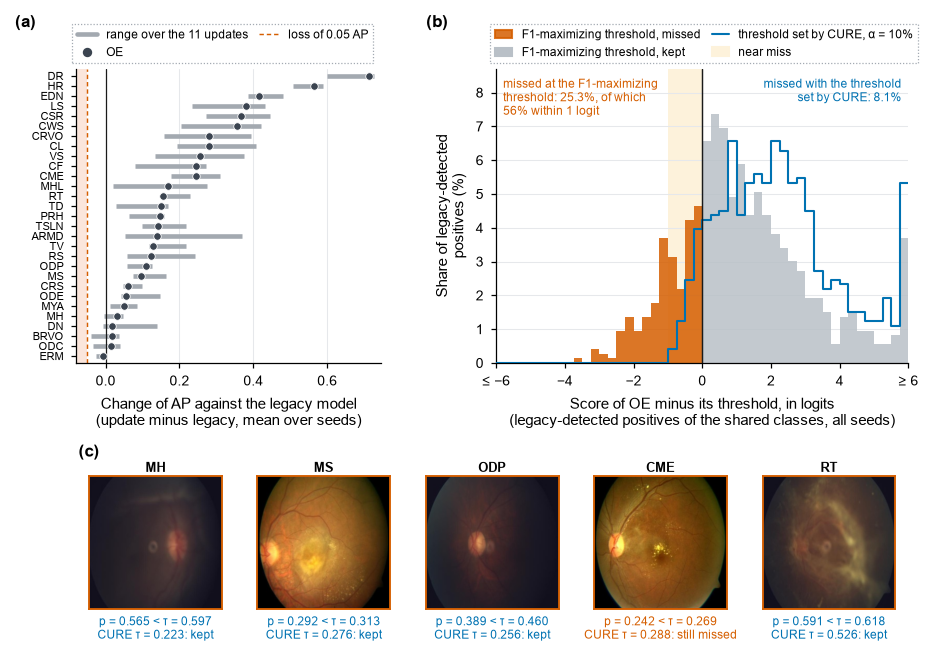

In [41]:
top_h = max(2.3, 0.075 * len(CLS7) + 0.75)                  # room for one readable row per class in (a)
fig = plt.figure(figsize=(COL2, top_h + 1.75))
outer = fig.add_gridspec(2, 1, height_ratios=[top_h, 1.32], hspace=0.62 * 2.5 / top_h)
top = outer[0].subgridspec(1, 2, width_ratios=[1.0, 1.35], wspace=0.32)
aA, aB = fig.add_subplot(top[0]), fig.add_subplot(top[1])

# (a) per-class change of AP
oe = dAP[dAP["update"] == "OE"].set_index("class")
cls_order = oe.sort_values("dAP").index.tolist() if len(oe) else sorted(dAP["class"].unique())
rng_ = dAP.groupby("class")["dAP"].agg(["min", "max"])
yy = np.arange(len(cls_order))
lo_x = min(-0.08, rng_["min"].min() - 0.02); hi_x = max(0.05, rng_["max"].max() + 0.02)
aA.axvspan(lo_x, -0.05, color="#FBE6DC", lw=0, zorder=0)
aA.hlines(yy, rng_.loc[cls_order, "min"], rng_.loc[cls_order, "max"], color=GREY, lw=2.2, zorder=2)
if len(oe):
    aA.scatter(oe.loc[cls_order, "dAP"], yy, s=13, color=COL["OE"], zorder=3, edgecolor="white", lw=0.4)
aA.axvline(0, color=INK, lw=0.6); aA.axvline(-0.05, color=BAD, lw=0.7, ls=(0, (3, 2)))
aA.set_yticks(yy); aA.set_yticklabels(cls_order, fontsize=5.4); aA.set_ylim(-0.7, len(cls_order) - 0.3)
aA.set_xlim(lo_x, hi_x); aA.set_xlabel("Change of AP against the legacy model\n(update minus legacy, mean over seeds)")
aA.grid(axis="x", color="#E6E8EB", lw=0.5); aA.set_axisbelow(True)
h = [Line2D([], [], color=GREY, lw=2.2, label="range over the 11 updates"),
     Line2D([], [], marker="o", ls="", color=COL["OE"], ms=3.5, label="OE"),
     Line2D([], [], color=BAD, lw=0.7, ls=(0, (3, 2)), label="loss of 0.05 AP")]
framed(aA.legend(handles=h, loc="lower left", bbox_to_anchor=(-0.02, 1.01), ncol=2, frameon=True, fancybox=False,
                 fontsize=5.8, handlelength=1.6, columnspacing=0.9, borderaxespad=0.2))
panel_tag(aA, "a", x=-0.20, y=1.13)

# (b) margins relative to the thresholds
bins = np.arange(-6, 6.0001, 0.25)
cf1, _ = np.histogram(np.clip(mg_f1, -5.99, 5.99), bins)
ccu, _ = np.histogram(np.clip(mg_cu, -5.99, 5.99), bins)
pf1, pcu = 100 * cf1 / len(mg_f1), 100 * ccu / len(mg_cu)
cent = (bins[:-1] + bins[1:]) / 2
aB.bar(cent, pf1, width=0.25, color=np.where(cent < 0, MISS_C, "#B9C0C7"), lw=0, zorder=2, alpha=0.85)
aB.step(bins, np.r_[pcu, pcu[-1]], where="post", color=CURE_C, lw=1.0, zorder=3)
aB.axvline(0, color=INK, lw=0.7, zorder=4)
aB.axvspan(-NEAR_LOGIT, 0, color="#FDF2DB", lw=0, zorder=0)
ymax_b = 1.18 * max(pf1.max(), pcu.max())
aB.set_ylim(0, ymax_b); aB.set_xlim(-6, 6)
aB.set_xticks(range(-6, 7, 2)); aB.set_xticklabels(["≤ −6", "−4", "−2", "0", "2", "4", "≥ 6"])
aB.text(-5.8, ymax_b * 0.97, f"missed at the F1-maximizing\nthreshold: {100 * miss_f1:.1f}%, of which\n{100 * near:.0f}% within {NEAR_LOGIT:g} logit",
        ha="left", va="top", fontsize=5.8, color=MISS_C)
aB.text(5.8, ymax_b * 0.97, f"missed with the threshold\nset by CURE: {100 * miss_cu:.1f}%", ha="right", va="top", fontsize=5.8, color=CURE_C)
aB.set_xlabel(f"Score of {UPDATE_7} minus its threshold, in logits\n(legacy-detected positives of the shared classes, all seeds)")
aB.set_ylabel("Share of legacy-detected\npositives (%)")
aB.grid(axis="y", color="#E6E8EB", lw=0.5); aB.set_axisbelow(True)
h = [mpl.patches.Patch(color=MISS_C, alpha=0.85, label="F1-maximizing threshold, missed"),
     mpl.patches.Patch(color="#B9C0C7", label="F1-maximizing threshold, kept"),
     Line2D([], [], color=CURE_C, lw=1.0, label="threshold set by CURE, α = 10%"),
     mpl.patches.Patch(color="#FDF2DB", label="near miss")]
framed(aB.legend(handles=h, loc="lower left", bbox_to_anchor=(-0.02, 1.01), ncol=2, frameon=True, fancybox=False,
                 fontsize=5.8, handlelength=1.4, columnspacing=0.9, borderaxespad=0.2))
panel_tag(aB, "b", x=-0.17, y=1.13)

# (c) near-miss images
bot = outer[1].subgridspec(1, max(N_NEAR, 1), wspace=0.06)
rec7 = []
for k, (i, j) in enumerate(near_list):
    ax = fig.add_subplot(bot[k])
    ax.imshow(Image.open(paths[i]).convert("RGB")); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(MISS_C); sp.set_linewidth(0.9)
    c = SH[j]
    kept_cure = d_cu[i, j] >= 0
    ax.set_title(f"{UNION[c]}", fontsize=6.4, fontweight="bold", loc="center", pad=2)
    ax.text(0.5, -0.05, f"p = {SIG(Lb[i, c]):.3f} < τ = {Tb[i, c]:.3f}\nCURE τ = {Tc[i, c]:.3f}: " +
            ("kept" if kept_cure else "still missed"), transform=ax.transAxes, ha="center", va="top", fontsize=5.6,
            color=CURE_C if kept_cure else MISS_C)
    rec7.append({"pool_index": i, "ID": pool["ID"][i], "split": pool["split"][i], "class": UNION[c], "p_OE": float(SIG(Lb[i, c])),
                 "thr_F1": float(Tb[i, c]), "thr_CURE": float(Tc[i, c]), "kept_with_CURE": bool(kept_cure)})
    if k == 0:
        panel_tag(ax, "c", x=-0.08, y=1.12)
print("class abbreviations in (c):", [r["class"] for r in rec7])
d7 = pd.concat([dAP.assign(part="a"), pd.DataFrame(mg_rows).assign(part="b"), pd.DataFrame(rec7).assign(part="c")], ignore_index=True)
save(fig, "fig07_regression_source", d7)
plt.show()

## Fig. 10 · Validity of the certificates, now across all risk levels (extended)

Top row as before: per-image risk of every test fold (dots), the pooled risk (black bar) and the limit (dashed), with the
share of the fifteen runs above the limit on top. Bottom row, new: (d) pooled risk achieved against the requested level
$\alpha$; the band spans the eleven updates under CRC, and the lines follow OE in both settings. Every point below the
diagonal keeps its promise. (e) New false alarms of CURE on OE at each level, with the band spanning the seeds; the cost
falls with about 195 calibration images (second setting) compared with about 46 (main setting).

*Suggested caption.* Fig. 10. Validity and cost of the certificates. (a) to (c) Per-image risk of every update with
CURE on each test fold. (d) Pooled risk against the requested level. (e) New false alarms against the requested level.

saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\fig10_validity.pdf


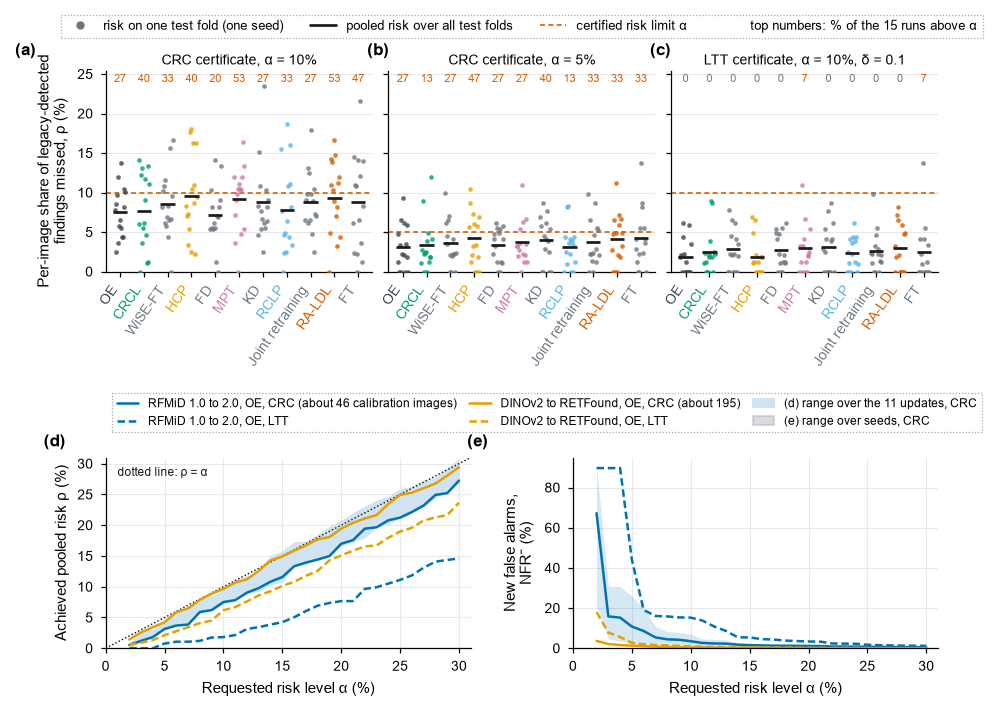

In [42]:
CERTS = [("CURE10", "CRC certificate, α = 10%", 10), ("CURE5", "CRC certificate, α = 5%", 5),
         ("CURE-LTT10", "LTT certificate, α = 10%, δ = 0.1", 10)]
v = info.copy()
v["base"] = v["variant"].str.split("+").str[0]
v["kind"] = v["variant"].str.split("+").str[1]
v["risk_%"] = 100 * v["test_risk"]
fig = plt.figure(figsize=(COL2, 5.0))
outer = fig.add_gridspec(2, 1, height_ratios=[1.0, 0.95], hspace=0.95)
top = outer[0].subgridspec(1, 3, wspace=0.06)
axs = [fig.add_subplot(top[0])]
axs += [fig.add_subplot(top[i], sharey=axs[0]) for i in (1, 2)]
ymax = max(13.0, v["risk_%"].max() * 1.08)
rng = np.random.default_rng(0)
for ax, (kind, title, a) in zip(axs, CERTS):
    for i, m in enumerate(order):
        r = v[(v.base == m) & (v.kind == kind)]["risk_%"].values
        jit = np.linspace(-0.22, 0.22, len(r)) if len(r) > 1 else np.zeros(1)
        ax.scatter(i + rng.permutation(jit), r, s=5, color=mcol(m) if m in COL else GREY_D, alpha=0.8, lw=0, zorder=3)
        ax.hlines(J10["means"][f"{m}+{kind}"]["risk"], i - 0.3, i + 0.3, color=INK, lw=1.3, zorder=4)
        share = J10["validity"][f"{m}+{kind}"][1]
        ax.text(i, ymax * 0.985, f"{100 * share:.0f}", ha="center", va="top", fontsize=5.4, color=BAD if share > 0 else GREY_D)
    ax.axhline(a, color=BAD, lw=0.8, ls=(0, (3, 2)), zorder=2)
    ax.set_xticks(range(len(order))); ax.set_xticklabels([nice(m) for m in order], rotation=55, ha="right")
    color_ticks(ax.get_xticklabels(), order)
    ax.set_title(title, loc="center", pad=3, fontsize=6.8); ax.set_ylim(0, ymax); ax.set_xlim(-0.6, len(order) - 0.4)
    ax.grid(axis="y", color="#E6E8EB", lw=0.5); ax.set_axisbelow(True)
for ax in axs[1:]:
    plt.setp(ax.get_yticklabels(), visible=False)
axs[0].set_ylabel("Per-image share of legacy-detected\nfindings missed, ρ (%)")
for ax, t_ in zip(axs, "abc"):
    panel_tag(ax, t_, x=-0.08 if t_ != "a" else -0.34, y=1.06)
h = [Line2D([], [], marker="o", ls="", color=GREY_D, ms=3, label="risk on one test fold (one seed)"),
     Line2D([], [], color=INK, lw=1.3, label="pooled risk over all test folds"),
     Line2D([], [], color=BAD, lw=0.8, ls=(0, (3, 2)), label="certified risk limit α"),
     Line2D([], [], ls="", label="top numbers: % of the 15 runs above α")]
framed(axs[1].legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, 1.13), ncol=4, frameon=True, fancybox=False))

# bottom row: risk-level sweep
bot = outer[1].subgridspec(1, 2, wspace=0.28)
aD, aE = fig.add_subplot(bot[0]), fig.add_subplot(bot[1])
A = 100 * ALPHA_GRID
crc_all = SW[(SW.setting == "main") & (SW.rule == "CRC")].groupby(["model", "alpha"])["risk"].mean().unstack(0)
aD.fill_between(A, crc_all.min(axis=1).values, crc_all.max(axis=1).values, color="#CFE3F1", lw=0, zorder=1)
STY_SW = {("main", "CRC"): dict(color=CURE_C, ls="-"), ("main", "LTT"): dict(color=CURE_C, ls=(0, (3, 1.5))),
          ("second", "CRC"): dict(color=FA_C, ls="-"), ("second", "LTT"): dict(color=FA_C, ls=(0, (3, 1.5)))}
for (st, rule), sty in STY_SW.items():
    s_ = SWm[(SWm.setting == st) & (SWm.model == "OE") & (SWm.rule == rule)].sort_values("alpha")
    aD.plot(100 * s_["alpha"], s_["risk"], lw=1.2, zorder=3, **sty)
aD.plot([0, 31], [0, 31], color=INK, lw=0.7, ls=(0, (1, 1.5)), zorder=2)
aD.set_xlim(0, 31); aD.set_ylim(0, 31); aD.set_aspect("auto")
aD.set_xlabel("Requested risk level α (%)"); aD.set_ylabel("Achieved pooled risk ρ (%)")
aD.grid(color="#E6E8EB", lw=0.5); aD.set_axisbelow(True)
aD.text(1.0, 29.5, "dotted line: ρ = α", ha="left", va="top", fontsize=5.8, color=INK)
for st, rule in (("main", "CRC"), ("second", "CRC")):
    s_ = SW[(SW.setting == st) & (SW.model == "OE") & (SW.rule == rule)]
    g = s_.groupby("alpha")["NFR-"]
    sty = STY_SW[(st, rule)]
    aE.fill_between(100 * g.min().index.values, g.min().values, g.max().values, color=sty["color"], alpha=0.16, lw=0)
for (st, rule), sty in STY_SW.items():
    s_ = SWm[(SWm.setting == st) & (SWm.model == "OE") & (SWm.rule == rule)].sort_values("alpha")
    aE.plot(100 * s_["alpha"], s_["NFR-"], lw=1.2, **sty)
aE.set_xlim(0, 31); aE.set_ylim(0, None)
aE.set_xlabel("Requested risk level α (%)")
aE.set_ylabel("New false alarms,\nNFR$^{-}$ (%)")
aE.grid(color="#E6E8EB", lw=0.5); aE.set_axisbelow(True)
panel_tag(aD, "d", x=-0.17, y=1.04); panel_tag(aE, "e", x=-0.29, y=1.04)
h = [Line2D([], [], color=CURE_C, lw=1.2, label="RFMiD 1.0 to 2.0, OE, CRC (about 46 calibration images)"),
     Line2D([], [], color=CURE_C, lw=1.2, ls=(0, (3, 1.5)), label="RFMiD 1.0 to 2.0, OE, LTT"),
     Line2D([], [], color=FA_C, lw=1.2, label="DINOv2 to RETFound, OE, CRC (about 195)"),
     Line2D([], [], color=FA_C, lw=1.2, ls=(0, (3, 1.5)), label="DINOv2 to RETFound, OE, LTT"),
     mpl.patches.Patch(color="#CFE3F1", label="(d) range over the 11 updates, CRC"),
     mpl.patches.Patch(color=GREY, alpha=0.4, label="(e) range over seeds, CRC")]
framed(aD.legend(handles=h, loc="lower left", bbox_to_anchor=(0.0, 1.10), ncol=3, frameon=True, fancybox=False,
                  fontsize=5.8, handlelength=1.8, columnspacing=1.0))
d10 = pd.concat([v[["variant", "seed", "fold", "alpha", "method", "lam", "n_cal", "feasible", "risk_%"]].assign(part="a-c"),
                 SW.assign(part="d-e")], ignore_index=True)
save(fig, "fig10_validity", d10)
plt.show()

## Fig. 12 · Examples on RFMiD 2.0 test images, with threshold rulers (revised)

Each column is one test image of seed `EXAMPLE_SEED` (chosen in the cell before Fig. 7). The chips give the decisions of the
legacy model, of OE at its F1-maximizing thresholds and of OE with CURE. The ruler below each image explains the change
for the finding that matters (restored or still missed): it marks the score of OE, its F1-maximizing threshold and the
threshold set by CURE on a logit scale. CURE never moves the score, only the threshold. The last column is a failure
case, where the finding stays below the CURE threshold.

*Suggested caption.* Fig. 12. Decisions on four RFMiD 2.0 test images. (a), (b) CURE restores a finding that OE missed
without a new false alarm; (c) it restores the finding and adds a false alarm; (d) the finding stays missed. The ruler
shows the score of the finding against both thresholds.

class abbreviations shown: ['BRVO', 'CWS', 'ERM', 'MH', 'ODE', 'ST']
saved C:\Users\Sajjad\Documents\Documents\paper-1\paper-1\outputs\figures\article\fig12_examples.pdf


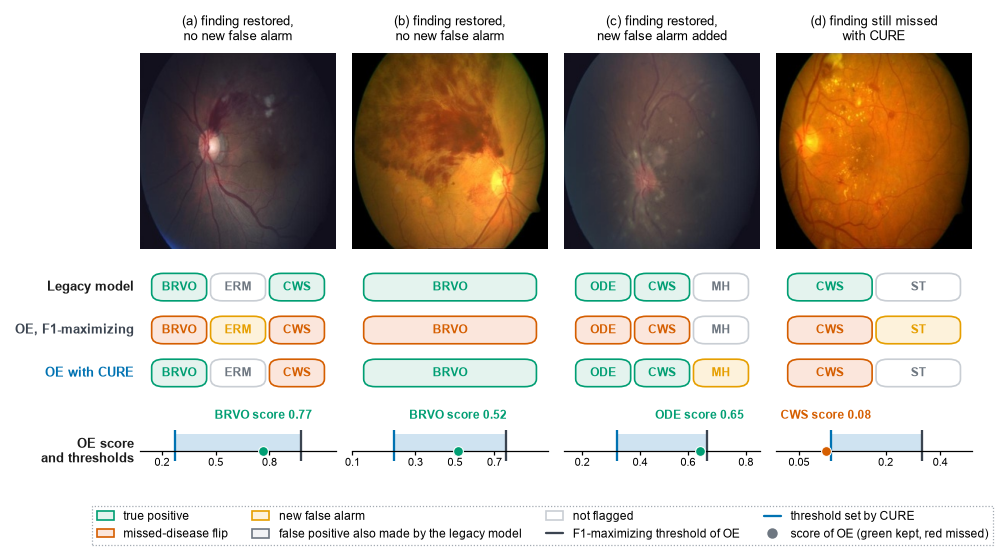

In [43]:
def state(i, j, P):
    if pos[i, j] and P[i, j]:
        return "tp"
    if pos[i, j] and P_old[i, j] and not P[i, j]:
        return "miss"
    if neg[i, j] and not P_old[i, j] and P[i, j]:
        return "fa"
    if neg[i, j] and P[i, j]:
        return "fp"
    return "off"
STY = {"tp": (KEPT_C, "#E4F3EE"), "miss": (MISS_C, "#FBE6DC"), "fa": (FA_C, "#FDF2DB"), "fp": (GREY_D, "#F2F3F5"),
       "off": ("#C9CED4", "white")}
PT = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99]

ncol = len(chosen)
fig = plt.figure(figsize=(COL2, 3.75))
gs = fig.add_gridspec(3, ncol, height_ratios=[1.0, 0.62, 0.36], hspace=0.08, wspace=0.08)
used = set()
rows_lab = [("Legacy model", P_old, INK), ("OE, F1-maximizing", P_oe, COL["OE"]), ("OE with CURE", P_cu, CURE_C)]
recs = []
for k, (i, kind) in enumerate(chosen):
    ax = fig.add_subplot(gs[0, k])
    ax.imshow(Image.open(paths[i]).convert("RGB")); ax.set_axis_off()
    ax.set_title(f"({chr(97 + k)}) {KIND[kind]}", fontsize=6.0, loc="center")
    key_j = [j for j in range(len(SH)) if (restored[i, j] if kind != "fail" else still[i, j])][:2]
    fa_j = [j for j in range(len(SH)) if fa_cu[i, j] or (neg[i, j] and P_oe[i, j] and not P_old[i, j])][:1]
    other = [j for j in range(len(SH)) if caught[i, j] and j not in key_j]
    cls = list(dict.fromkeys(key_j + fa_j + other))[:4]
    used.update(UNION[SH[j]] for j in cls)
    bx = fig.add_subplot(gs[1, k]); bx.set_xlim(0, 1); bx.set_ylim(0, 3); bx.set_axis_off()
    w = 0.9 / max(len(cls), 1)
    for r_, (lab, P, lc) in enumerate(rows_lab):
        yy = 2.5 - r_
        if k == 0:
            bx.text(-0.03, yy, lab, ha="right", va="center", fontsize=6.0, fontweight="bold", color=lc)
        for c_, j in enumerate(cls):
            st = state(i, j, P)
            ec, fc = STY[st]
            x0 = 0.05 + c_ * w
            bx.add_patch(FancyBboxPatch((x0 + 0.01, yy - 0.32), w - 0.02, 0.64, boxstyle="round,pad=0,rounding_size=0.06",
                                        fc=fc, ec=ec, lw=0.8, mutation_aspect=3))
            bx.text(x0 + w / 2, yy, UNION[SH[j]], ha="center", va="center", fontsize=5.6, color=ec if st != "off" else GREY_D,
                    fontweight="bold")
            recs.append({"panel": chr(97 + k), "pool_index": i, "ID": pool["ID"][i], "split": pool["split"][i],
                         "row": lab, "class": UNION[SH[j]], "state": st})
    # threshold ruler for the key finding
    j = key_j[0]; c = SH[j]
    z_s, z_f1, z_cu = float(Lb[i, c]), float(LOGIT(Tb[i, c])), float(LOGIT(Tc[i, c]))
    lo_, hi_ = min(z_s, z_f1, z_cu) - 0.9, max(z_s, z_f1, z_cu) + 0.9
    rx = fig.add_subplot(gs[2, k])
    rx.set_xlim(lo_, hi_); rx.set_ylim(-1, 1.6)
    for sp in ("left", "right", "top"):
        rx.spines[sp].set_visible(False)
    rx.spines["bottom"].set_position(("data", 0)); rx.set_yticks([])
    ticks = [LOGIT(p) for p in PT if lo_ <= LOGIT(p) <= hi_]
    ticks = ticks[::int(np.ceil(len(ticks) / 4))] if len(ticks) > 4 else ticks
    rx.xaxis.set_major_locator(FixedLocator(ticks)); rx.xaxis.set_minor_locator(NullLocator())
    rx.set_xticklabels([f"{SIG(t):g}" for t in ticks], fontsize=5.4)
    rx.tick_params(axis="x", length=2, pad=1)
    rx.axvspan(min(z_f1, z_cu), max(z_f1, z_cu), ymin=0.38, ymax=0.62, color="#CFE3F1", lw=0)
    rx.vlines(z_f1, -0.35, 0.75, color=COL["OE"], lw=1.1)
    rx.vlines(z_cu, -0.35, 0.75, color=CURE_C, lw=1.1)
    kept = z_s >= z_cu
    rx.scatter([z_s], [0], s=22, marker="o", color=KEPT_C if kept else MISS_C, zorder=4, edgecolor="white", lw=0.5)
    rx.text(z_s, 1.05, f"{UNION[c]} score {SIG(z_s):.2f}", ha="center", va="bottom", fontsize=5.6,
            color=KEPT_C if kept else MISS_C, fontweight="bold")
    recs.append({"panel": chr(97 + k), "pool_index": i, "ID": pool["ID"][i], "split": pool["split"][i], "row": "ruler",
                 "class": UNION[c], "state": "kept" if kept else "missed", "p_OE": SIG(z_s), "thr_F1": Tb[i, c], "thr_CURE": Tc[i, c]})
    if k == 0:
        rx.text(lo_ - 0.03 * (hi_ - lo_), 0, "OE score\nand thresholds", ha="right", va="center", fontsize=6.0,
                fontweight="bold", color=INK)
h = [FancyBboxPatch((0, 0), 1, 1, fc=STY[s][1], ec=STY[s][0], lw=0.8, label=l) for s, l in
     [("tp", "true positive"), ("miss", "missed-disease flip"), ("fa", "new false alarm"),
      ("fp", "false positive also made by the legacy model"), ("off", "not flagged")]]
h += [Line2D([], [], color=COL["OE"], lw=1.1, label="F1-maximizing threshold of OE"),
      Line2D([], [], color=CURE_C, lw=1.1, label="threshold set by CURE"),
      Line2D([], [], marker="o", ls="", color=GREY_D, ms=4, label="score of OE (green kept, red missed)")]
framed(fig.legend(handles=h, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.075), frameon=True, fancybox=False,
                  fontsize=5.8, handlelength=1.4))
print("class abbreviations shown:", sorted(used))
save(fig, "fig12_examples", pd.DataFrame(recs))
plt.show()

## Former Fig. 7 becomes Fig. S4

In [44]:
RENAME = {"fig07_ablation": "figS1_ablation", "figS1_forest": "figS2_forest",
          "figS2_accuracy_regression": "figS3_accuracy_regression"}
for old, new in RENAME.items():
    for ext in ("pdf", "png"):
        src = FIG / f"{old}.{ext}"
        if src.exists():
            shutil.copyfile(src, FIG / f"{new}.{ext}")
        else:
            print(f"{src.name} not found: run notebook 11 once, then this cell again")
for ext in ("pdf", "png"):                      # Fig. S3 (calibration size) is replaced by Fig. 10(e)
    (FIG / f"figS3_calibration_size.{ext}").unlink(missing_ok=True)
(FIG / "figS4_ablation.pdf").unlink(missing_ok=True); (FIG / "figS4_ablation.png").unlink(missing_ok=True)
for name in ["fig07_regression_source", "fig10_validity", "fig12_examples"] + list(RENAME.values()):
    print(("ok      " if (FIG / f"{name}.pdf").exists() else "missing ") + name)

ok      fig07_regression_source
ok      fig10_validity
ok      fig12_examples
ok      figS1_ablation
ok      figS2_forest
ok      figS3_accuracy_regression
